# FIFA 21 Player Dataset: Data Cleaning and Transformation

## Project overview

In this project, I am cleaning and transforming the FIFA 21 player dataset using Python and Pandas. The purpose is to improve the structure and consistency of the data so that it is easier to explore, analyze, and use in future data analysis or machine learning tasks.

I will inspect the dataset, identify inconsistent formats, handle missing values carefully, convert columns to appropriate data types, and create useful features where appropriate.

## Tools and libraries

I use:
- **Pandas** for loading, inspecting, and transforming tabular data.
- **NumPy** for numerical operations and missing-value handling.
- **Matplotlib** for data visualization.
- **Regular expressions (`re`)** for extracting information from text.

I will document the reason for each transformation and validate the results rather than changing columns without understanding them.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

## 1. Load the dataset

I begin by loading the FIFA 21 player dataset into a Pandas DataFrame. I then inspect its dimensions and column names to understand the amount of data available and the information recorded for each player.

In [2]:
df = pd.read_csv("rawDataset/fifa21 raw data.csv")

print("Shape: ", df.shape)
print("\nColumns names: ")
print(df.columns.tolist())


Shape:  (18979, 75)

Columns names: 
['ID', 'Name', 'LongName', 'photoUrl', 'playerUrl', 'Nationality', 'Age', 'POT', 'Contract', 'Positions', 'Height', 'Weight', 'Preferred Foot', 'BOV', 'Best Position', 'Joined', 'Loan Date End', 'Value', 'Wage', 'Release Clause', 'Attacking', 'Crossing', 'Finishing', 'Heading Accuracy', 'Short Passing', 'Volleys', 'Skill', 'Dribbling', 'Curve', 'FK Accuracy', 'Long Passing', 'Ball Control', 'Movement', 'Acceleration', 'Sprint Speed', 'Agility', 'Reactions', 'Balance', 'Power', 'Shot Power', 'Jumping', 'Stamina', 'Strength', 'Long Shots', 'Mentality', 'Aggression', 'Interceptions', 'Positioning', 'Vision', 'Penalties', 'Composure', 'Defending', 'Marking', 'Standing Tackle', 'Sliding Tackle', 'Goalkeeping', 'GK Diving', 'GK Handling', 'GK Kicking', 'GK Positioning', 'GK Reflexes', 'Total Stats', 'Base Stats', 'W/F', 'SM', 'A/W', 'D/W', 'IR', 'PAC', 'SHO', 'PAS', 'DRI', 'DEF', 'PHY', 'Hits']


C:\Users\Dell\AppData\Local\Temp\ipykernel_1936\822910095.py:1: DtypeWarning: Columns (74) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("rawDataset/fifa21 raw data.csv")


## 2. Initial dataset overview

The dataset contains **18,979 rows and 75 columns**. Each row represents a player, while the columns contain information such as player details, club information, contract data, market value, wages, physical attributes, and in-game ratings.

Before cleaning individual columns, I inspect the available data types. This helps me identify columns that may need conversion or further investigation.

In [4]:
print("Data type: ")
print(df.dtypes)
print(df.dtypes.value_counts())

Data type: 
ID            int64
Name         object
LongName     object
photoUrl     object
playerUrl    object
              ...  
PAS           int64
DRI           int64
DEF           int64
PHY           int64
Hits         object
Length: 75, dtype: object
int64     53
object    22
Name: count, dtype: int64


The initial inspection shows that the dataset contains both numerical and object columns. There are **53 integer columns and 22 object columns**.

I will begin by examining the object columns because some of them may contain numbers stored as text, symbols, abbreviations, or values expressed in different units. My goal is not to convert every object column into a number; I will choose an appropriate data type based on the meaning of each attribute.

In [5]:
print(df.select_dtypes(include="object").head())

                Name                      LongName  \
0           L. Messi                  Lionel Messi   
1  Cristiano Ronaldo  C. Ronaldo dos Santos Aveiro   
2           J. Oblak                     Jan Oblak   
3       K. De Bruyne               Kevin De Bruyne   
4          Neymar Jr    Neymar da Silva Santos Jr.   

                                           photoUrl  \
0  https://cdn.sofifa.com/players/158/023/21_60.png   
1  https://cdn.sofifa.com/players/020/801/21_60.png   
2  https://cdn.sofifa.com/players/200/389/21_60.png   
3  https://cdn.sofifa.com/players/192/985/21_60.png   
4  https://cdn.sofifa.com/players/190/871/21_60.png   

                                           playerUrl Nationality     Contract  \
0  http://sofifa.com/player/158023/lionel-messi/2...   Argentina  2004 ~ 2021   
1  http://sofifa.com/player/20801/c-ronaldo-dos-s...    Portugal  2018 ~ 2022   
2  http://sofifa.com/player/200389/jan-oblak/210006/    Slovenia  2014 ~ 2023   
3  http://sofifa.com

## 3. Cleaning financial attributes

The first object columns I investigate include player **Value**, **Wage**, and **Release Clause**. These columns contain financial amounts represented as text, including the euro symbol (`€`) and suffixes such as `M` for millions and `K` for thousands.

I will inspect each column before applying a conversion. The aim is to represent these amounts as numerical values while keeping their meaning in euros.

In [6]:
print(df['Value'].head(15))
print(df['Value'].value_counts().head(15))

0     €103.5M
1        €63M
2       €120M
3       €129M
4       €132M
5       €111M
6     €120.5M
7       €102M
8     €185.5M
9       €110M
10      €113M
11    €120.5M
12     €90.5M
13       €82M
14     €17.5M
Name: Value, dtype: object
Value
€1.2M    582
€1.1M    559
€1.3M    534
€1.6M    532
€1M      497
€1.4M    467
€1.5M    392
€325K    392
€475K    386
€500K    383
€550K    338
€1.9M    332
€300K    331
€375K    318
€525K    318
Name: count, dtype: int64


In [7]:
print(df['Value'].nunique())
print(df['Value'].dropna().unique())

255
['€103.5M' '€63M' '€120M' '€129M' '€132M' '€111M' '€120.5M' '€102M'
 '€185.5M' '€110M' '€113M' '€90.5M' '€82M' '€17.5M' '€83.5M' '€33.5M'
 '€114.5M' '€78M' '€103M' '€109M' '€92M' '€10M' '€76.5M' '€89.5M' '€87.5M'
 '€79.5M' '€124M' '€114M' '€95M' '€92.5M' '€105.5M' '€88.5M' '€85M'
 '€81.5M' '€26M' '€21M' '€56M' '€67.5M' '€53M' '€36.5M' '€51M' '€65.5M'
 '€46.5M' '€61.5M' '€72.5M' '€77.5M' '€43.5M' '€32.5M' '€36M' '€32M'
 '€54M' '€49.5M' '€57M' '€66.5M' '€74.5M' '€71.5M' '€121M' '€99M' '€67M'
 '€86.5M' '€93.5M' '€70M' '€62M' '€66M' '€58M' '€44M' '€81M' '€37M'
 '€14.5M' '€46M' '€47.5M' '€52.5M' '€54.5M' '€34.5M' '€57.5M' '€51.5M'
 '€44.5M' '€55M' '€48M' '€60.5M' '€63.5M' '€61M' '€29M' '€58.5M' '€55.5M'
 '€42M' '€40.5M' '€43M' '€45.5M' '€34M' '€26.5M' '€42.5M' '€35.5M' '€45M'
 '€41.5M' '€40M' '€11M' '€13.5M' '€29.5M' '€27M' '€15.5M' '€38.5M' '€52M'
 '€33M' '€19M' '€73.5M' '€38M' '€35M' '€47M' '€24M' '€30.5M' '€18M' '€28M'
 '€25.5M' '€25M' '€31M' '€23.5M' '€30M' '€31.5M' '€22.5M' '€28.5M

### Understanding the Value format

The `Value` column uses a currency symbol and abbreviated suffixes. I identified three parts that need to be interpreted:

- `€` represents the euro currency symbol.
- `M` represents one million.
- `K` represents one thousand.

For example, `€103.5M` should become `103500000`.

My conversion logic is to remove the currency symbol, multiply values ending in `M` by 1,000,000, multiply values ending in `K` by 1,000, and convert values without either suffix directly to a number.

In [8]:
def convert_value(value):
    # remove euro sign
    value = value.replace("€","")
    #convet millions
    if 'M' in value:
        return float(value.replace("M", "")) * 1000000
    # convert to 1000s
    elif 'K' in value:
        return float(value.replace("K", "")) * 1000
    else:
        return float(value)
        

In [9]:
# before applying lets check if we have any missing value in this data frame.
#A missing value would cause this function to fail.
df["Value"].isna().sum()

np.int64(0)

In [10]:
# apply it to our dataframe
df["Value"] = df["Value"].apply(convert_value)

**Data-cleaning note:** When possible, it is useful to preserve the original column or create a cleaned copy before replacing values. Keeping the original data makes it easier to compare the raw and transformed values and to investigate unexpected results. In this notebook, I apply the transformations directly to the working DataFrame.

In [11]:
#                               lets check if our changes happened as we meant
# Check for missing values
print("Missing values: ", df["Value"].isna().sum())
print(df["Value"].head(10))
print("\n Data Type", df["Value"].dtype)
print("descriptive statistic: ")
print(df["Value"].describe())

Missing values:  0
0    103500000.0
1     63000000.0
2    120000000.0
3    129000000.0
4    132000000.0
5    111000000.0
6    120500000.0
7    102000000.0
8    185500000.0
9    110000000.0
Name: Value, dtype: float64

 Data Type float64
descriptive statistic: 
count    1.897900e+04
mean     2.865063e+06
std      7.685154e+06
min      0.000000e+00
25%      4.750000e+05
50%      9.500000e+05
75%      2.000000e+06
max      1.855000e+08
Name: Value, dtype: float64


### Cleaning Wage

After inspecting `Wage`, I check whether its values use the same currency and suffix conventions as `Value`. I also check for missing values before reusing the `convert_value()` function.

If the formats are consistent, I can apply the same conversion logic and then verify the resulting data type and numerical distribution.

In [12]:
print(df["Wage"].head())
print(df["Wage"].nunique())
print(df["Wage"].unique())

0    €560K
1    €220K
2    €125K
3    €370K
4    €270K
Name: Wage, dtype: object
134
['€560K' '€220K' '€125K' '€370K' '€270K' '€240K' '€250K' '€160K' '€260K'
 '€210K' '€310K' '€130K' '€350K' '€300K' '€190K' '€145K' '€195K' '€100K'
 '€140K' '€290K' '€82K' '€110K' '€230K' '€155K' '€200K' '€165K' '€95K'
 '€170K' '€105K' '€115K' '€150K' '€135K' '€55K' '€58K' '€81K' '€34K'
 '€120K' '€59K' '€90K' '€65K' '€56K' '€71K' '€18K' '€75K' '€47K' '€20K'
 '€84K' '€86K' '€74K' '€78K' '€27K' '€68K' '€85K' '€25K' '€46K' '€83K'
 '€54K' '€79K' '€175K' '€43K' '€49K' '€45K' '€38K' '€41K' '€39K' '€23K'
 '€51K' '€50K' '€87K' '€30K' '€14K' '€69K' '€31K' '€64K' '€53K' '€35K'
 '€21K' '€28K' '€17K' '€33K' '€70K' '€32K' '€89K' '€26K' '€40K' '€76K'
 '€72K' '€48K' '€36K' '€29K' '€60K' '€16K' '€37K' '€24K' '€52K' '€0'
 '€62K' '€73K' '€63K' '€19K' '€1K' '€66K' '€80K' '€12K' '€2K' '€42K'
 '€13K' '€900' '€57K' '€77K' '€61K' '€22K' '€67K' '€44K' '€15K' '€11K'
 '€8K' '€850' '€10K' '€88K' '€500' '€7K' '€6K' '€9K' '€5K' '€70

In [13]:
# checking if we have any missing value in this column.
print(df["Wage"].isna().sum())

0


In [14]:
df["Wage"] = df["Wage"].apply(convert_value)

In [15]:
# VALIDATE
print("Data type: ", df["Wage"].dtype)
print(df["Wage"].describe())
print(df["Wage"].head(10))

Data type:  float64
count     18979.000000
mean       9092.062279
std       19707.021089
min           0.000000
25%        1000.000000
50%        3000.000000
75%        8000.000000
max      560000.000000
Name: Wage, dtype: float64
0    560000.0
1    220000.0
2    125000.0
3    370000.0
4    270000.0
5    240000.0
6    250000.0
7    160000.0
8    160000.0
9    260000.0
Name: Wage, dtype: float64


### Cleaning Release Clause

I now inspect `Release Clause` to confirm that it uses the same currency symbols and `M`/`K` suffixes as `Value`. If the formats are consistent and there are no missing values that would break the conversion function, I can reuse `convert_value()` rather than writing a second function.

In [16]:
# Next is Release Clause
print(df["Release Clause"].head(15))
print(df["Release Clause"].nunique())
print(df["Release Clause"].unique())

0     €138.4M
1      €75.9M
2     €159.4M
3       €161M
4     €166.5M
5       €132M
6     €144.3M
7     €120.3M
8     €203.1M
9     €147.7M
10    €145.3M
11    €144.3M
12      €122M
13      €119M
14     €47.9M
Name: Release Clause, dtype: object
1216
['€138.4M' '€75.9M' '€159.4M' ... '€59K' '€35K' '€64K']


In [17]:
df["Release Clause"] = df["Release Clause"].apply(convert_value)

In [18]:
# VALIDATE
print("Data type: ", df["Release Clause"].dtype)
print(df["Release Clause"].describe())
print(df["Release Clause"].head(10))

Data type:  float64
count    1.897900e+04
mean     3.962951e+06
std      9.772762e+06
min      0.000000e+00
25%      4.235000e+05
50%      1.000000e+06
75%      2.800000e+06
max      2.031000e+08
Name: Release Clause, dtype: float64
0    138400000.0
1     75900000.0
2    159400000.0
3    161000000.0
4    166500000.0
5    132000000.0
6    144300000.0
7    120300000.0
8    203100000.0
9    147700000.0
Name: Release Clause, dtype: float64


## 4. Standardizing Weight

I inspect the `Weight` column to identify its measurement units, missing values, and distinct formats. The dataset contains both kilograms and pounds, so I need to standardize the values before using this attribute in numerical analysis.

In [19]:
print("All of Data is : ", df.shape[0])
print("Missing Vaue: ", df["Weight"].isna().sum())
print("Number of weights which is in KG: ", df["Weight"].str.endswith("kg").sum())
print("In Pound: ", df["Weight"].str.endswith("lbs").sum())
print("How many different weight we have: ", df["Weight"].nunique())
print("_" * 80)
print(df["Weight"].unique())

All of Data is :  18979
Missing Vaue:  0
Number of weights which is in KG:  18939
In Pound:  40
How many different weight we have:  79
________________________________________________________________________________
['72kg' '83kg' '87kg' '70kg' '68kg' '80kg' '71kg' '91kg' '73kg' '85kg'
 '92kg' '69kg' '84kg' '96kg' '81kg' '82kg' '75kg' '86kg' '89kg' '74kg'
 '76kg' '64kg' '78kg' '90kg' '66kg' '60kg' '94kg' '79kg' '67kg' '65kg'
 '59kg' '61kg' '93kg' '88kg' '97kg' '77kg' '62kg' '63kg' '95kg' '100kg'
 '58kg' '183lbs' '179lbs' '172lbs' '196lbs' '176lbs' '185lbs' '170lbs'
 '203lbs' '168lbs' '161lbs' '146lbs' '130lbs' '190lbs' '174lbs' '148lbs'
 '165lbs' '159lbs' '192lbs' '181lbs' '139lbs' '154lbs' '157lbs' '163lbs'
 '98kg' '103kg' '99kg' '102kg' '56kg' '101kg' '57kg' '55kg' '104kg'
 '107kg' '110kg' '53kg' '50kg' '54kg' '52kg']


### Standardizing Weight units

The `Weight` column contains values in both kilograms (`kg`) and pounds (`lbs`). Mixing measurement units in one column makes comparisons and numerical analysis difficult.

I will use **kilograms as the standard unit**:
- Values already expressed in kilograms remain unchanged after removing the unit suffix.
- Values expressed in pounds are multiplied by `0.45359237` to convert them to kilograms.

This gives the column one consistent unit of measurement.

In [20]:
def convert_weight(weight):
    #Extract numeric value
    numeric_value = float(weight[:-2] if weight.endswith("kg") else weight[:-3])

    #convert pounds to kg
    if weight.endswith("lbs"):
        return numeric_value * 0.45359237
    else:
        return numeric_value

In [21]:
df["Weight"] = df["Weight"].apply(convert_weight)

In [22]:
print(df["Weight"].dtype)

print(df["Weight"].describe())

print(df["Weight"].head(15))

float64
count    18979.000000
mean        75.019129
std          7.073554
min         50.000000
25%         70.000000
50%         75.000000
75%         80.000000
max        110.000000
Name: Weight, dtype: float64
0     72.0
1     83.0
2     87.0
3     70.0
4     68.0
5     80.0
6     71.0
7     91.0
8     73.0
9     85.0
10    92.0
11    69.0
12    84.0
13    96.0
14    92.0
Name: Weight, dtype: float64


## 5. Standardizing Height

Before converting `Height`, I inspect its sample values, missing values, unique values, and formats. This helps me confirm whether the column contains centimeters, feet and inches, or both.

In [23]:
print("Five first data points:\n",df["Height"].head())
print("Missing Value",df["Height"].isna().sum())
print("Number of unique value: ", df["Height"].nunique())
print("_"* 80)
print(df["Height"].unique())
print("_"* 80)
df[df["Height"].astype(str).str.contains("'")]["Height"].unique()

Five first data points:
 0    170cm
1    187cm
2    188cm
3    181cm
4    175cm
Name: Height, dtype: object
Missing Value 0
Number of unique value:  62
________________________________________________________________________________
['170cm' '187cm' '188cm' '181cm' '175cm' '184cm' '191cm' '178cm' '193cm'
 '185cm' '199cm' '173cm' '168cm' '176cm' '177cm' '183cm' '180cm' '189cm'
 '179cm' '195cm' '172cm' '182cm' '186cm' '192cm' '165cm' '194cm' '167cm'
 '196cm' '163cm' '190cm' '174cm' '169cm' '171cm' '197cm' '200cm' '166cm'
 '6\'2"' '164cm' '198cm' '6\'3"' '6\'5"' '5\'11"' '6\'4"' '6\'1"' '6\'0"'
 '5\'10"' '5\'9"' '5\'6"' '5\'7"' '5\'4"' '201cm' '158cm' '162cm' '161cm'
 '160cm' '203cm' '157cm' '156cm' '202cm' '159cm' '206cm' '155cm']
________________________________________________________________________________


array(['6\'2"', '6\'3"', '6\'5"', '5\'11"', '6\'4"', '6\'1"', '6\'0"',
       '5\'10"', '5\'9"', '5\'6"', '5\'7"', '5\'4"'], dtype=object)

### Standardizing Height units

The `Height` column contains two different formats: centimeters (for example, `180cm`) and feet-and-inches (for example, `6'3"`). To make the values comparable, I will convert all heights to **centimeters**.

The conversion uses these relationships:
- 1 foot = 12 inches
- 1 inch = 2.54 centimeters

**Example: converting 6'3" to centimeters**

1. Convert feet to inches: \(6 \times 12 = 72\) inches.
2. Add the remaining inches: \(72 + 3 = 75\) inches.
3. Convert inches to centimeters: \(75 \times 2.54 = 190.5\) cm.

The standardized value is therefore **190.5 cm**.

In [24]:
def convert_height(height):
    #handle centimeter value
    if height.endswith("cm"):
        return float(height[:-2])
    #handle feet and inches
    else:
        numbers = re.findall(r"\d+", height)
        feet = int(numbers[0])
        inches = int(numbers[1])
        total_inches = (feet * 12) + inches
        return total_inches * 2.54
        

In [25]:
df["Height"] = df["Height"].apply(convert_height)

In [26]:
print(df["Height"].dtype)

print(df["Height"].describe())

print(df["Height"].head(15))

print(df["Height"].isna().sum())

float64
count    18979.000000
mean       181.200409
std          6.840192
min        155.000000
25%        176.000000
50%        181.000000
75%        186.000000
max        206.000000
Name: Height, dtype: float64
0     170.0
1     187.0
2     188.0
3     181.0
4     175.0
5     184.0
6     175.0
7     191.0
8     178.0
9     187.0
10    193.0
11    175.0
12    185.0
13    199.0
14    193.0
Name: Height, dtype: float64
0


## 6. Exploring and transforming Contract

The `Contract` column contains different kinds of contract information. Before changing it, I inspect its data type, missing values, unique values, and most frequent entries.

This exploration helps me identify the formats used in the column. I will then separate the information into more useful fields, including contract status, contract start year, contract end year, and loan expiration date where available.

In [27]:
print(df["Contract"].value_counts().head(10))
print("_"*80)
print("Missing Value: ",df["Contract"].isna().sum())
print("Data type: ",df["Contract"].dtype)
print("_"*80)


print(df["Contract"].nunique())
print(df["Contract"].unique())
print("_"*80)
df["Contract"].value_counts().head(30)

Contract
2019 ~ 2021             1706
2020 ~ 2022             1445
2020 ~ 2021             1440
2019 ~ 2022             1236
2018 ~ 2021             1163
2020 ~ 2023             1162
2019 ~ 2023             1144
2020 ~ 2024             1009
Jun 30, 2021 On Loan     770
2019 ~ 2024              672
Name: count, dtype: int64
________________________________________________________________________________
Missing Value:  0
Data type:  object
________________________________________________________________________________
131
['2004 ~ 2021' '2018 ~ 2022' '2014 ~ 2023' '2015 ~ 2023' '2017 ~ 2022'
 '2017 ~ 2023' '2018 ~ 2024' '2014 ~ 2022' '2018 ~ 2023' '2016 ~ 2023'
 '2013 ~ 2023' '2011 ~ 2023' '2009 ~ 2022' '2005 ~ 2021' '2011 ~ 2021'
 '2015 ~ 2022' '2017 ~ 2024' '2010 ~ 2024' '2012 ~ 2021' '2019 ~ 2024'
 '2015 ~ 2024' '2017 ~ 2025' '2020 ~ 2025' '2019 ~ 2023' '2008 ~ 2023'
 '2015 ~ 2021' '2020 ~ 2022' '2012 ~ 2022' '2016 ~ 2025' '2013 ~ 2022'
 '2011 ~ 2022' '2012 ~ 2024' '2016 ~ 2021' '20

Contract
2019 ~ 2021             1706
2020 ~ 2022             1445
2020 ~ 2021             1440
2019 ~ 2022             1236
2018 ~ 2021             1163
2020 ~ 2023             1162
2019 ~ 2023             1144
2020 ~ 2024             1009
Jun 30, 2021 On Loan     770
2019 ~ 2024              672
2017 ~ 2021              661
2018 ~ 2022              609
2018 ~ 2023              469
2017 ~ 2022              405
2020 ~ 2020              361
2016 ~ 2021              361
2019 ~ 2020              350
2020 ~ 2025              325
2017 ~ 2023              270
Free                     237
2018 ~ 2020              229
2018 ~ 2024              224
2016 ~ 2022              205
2015 ~ 2021              196
2016 ~ 2023              155
2014 ~ 2021              146
2015 ~ 2022              123
2017 ~ 2020              121
2017 ~ 2024              111
2019 ~ 2025              110
Name: count, dtype: int64

### Identifying contract formats

The inspection shows that the `Contract` column contains different formats. I check how many records contain a regular contract period (using `~`), how many are marked `On Loan`, and how many are marked `Free`.

Counting these patterns helps me understand the main contract categories before creating a separate status column.

In [28]:
print(df["Contract"].str.contains("~").sum())
print(df["Contract"].str.contains("On Loan").sum())
print((df["Contract"] == "Free").sum())

17729
1013
237


### Creating Contract Status

The original `Contract` column combines several contractual situations in one field. I create a new `Contract Status` column to classify each player as:

- `Regular` — the value represents a regular contract period.
- `On Loan` — the contract text indicates that the player is on loan.
- `Free` — the player is listed as a free agent.

Separating status from the original text makes the information easier to filter and analyze. I keep the original `Contract` column so the source information remains available.

In [29]:
df["Contract Status"] = "Regular"
df.loc[df["Contract"].str.contains("On Loan"), "Contract Status"] = "On Loan"
df.loc[df["Contract"] == "Free", "Contract Status"] = "Free"
df["Contract Status"].value_counts()

Contract Status
Regular    17729
On Loan     1013
Free         237
Name: count, dtype: int64

### Extracting Contract Start and End Years

For regular contracts, the `Contract` column contains a start year and an end year, commonly written in a form such as `2018 ~ 2022`.

I use regular expressions with `str.extract()` to create two separate columns:
- `Contract Start Year`
- `Contract End Year`

Records that do not contain a regular contract period, such as free agents or loan players, may have missing values in these new columns. These missing values are expected when the relevant year information is not present in the original text.

In [30]:
df["Contract Start Year"] = df["Contract"].str.extract(r"(\d{4})")
df["Contract End Year"] = df["Contract"].str.extract(r"~\s*(\d{4})")
df[["Contract", "Contract Start Year", "Contract End Year"]].head()

,Contract,Contract Start Year,Contract End Year
0,2004 ~ 2021,2004,2021
1,2018 ~ 2022,2018,2022
2,2014 ~ 2023,2014,2023
3,2015 ~ 2023,2015,2023
4,2017 ~ 2022,2017,2022


### Converting Contract Years to Numeric Data Types

The extracted contract years are initially stored as text. I use `pd.to_numeric()` to convert them into numerical values so that I can perform calculations, including calculating contract duration.

Values that could not be extracted remain missing. I preserve these missing values because the original contract text does not provide regular start or end years for every player.

**Validation point to review:** The current `Contract Start Year` extraction pattern captures the first four-digit year in each `Contract` value. For a loan record, that may be the year in the loan-expiration date rather than a regular contract start year. Before treating this feature as a true contract start year in analysis, I should restrict extraction to records classified as `Regular` and validate the loan records separately.


In [31]:
df["Contract Start Year"] = pd.to_numeric(df["Contract Start Year"])
df["Contract End Year"] = pd.to_numeric(df["Contract End Year"])
print(df[["Contract Start Year", "Contract End Year"]].dtypes)
print(df[["Contract Start Year", "Contract End Year"]].describe())

Contract Start Year    float64
Contract End Year      float64
dtype: object
       Contract Start Year  Contract End Year
count         18742.000000       17729.000000
mean           2018.465745        2022.064414
std               2.117809           1.276312
min            1998.000000        2020.000000
25%            2018.000000        2021.000000
50%            2019.000000        2022.000000
75%            2020.000000        2023.000000
max            2023.000000        2028.000000


### Extracting Loan Expiration Dates

Loan records contain an expiration date followed by the text `On Loan`. I use `str.extract()` with a regular expression to capture the date and store it in a separate `Loan End Date` column.

This keeps loan expiration information separate from regular contract start and end years. Players who are not listed as being on loan are expected to have missing values in this column.

In [32]:
df["Loan End Date"] = df["Contract"].str.extract(r"([A-Za-z]{3}\s+\d{1,2},\s+\d{4})(?=\s+On Loan)")

### Converting Loan End Dates to Datetime

The extracted loan expiration dates are still represented as strings. I convert them to Pandas datetime values using the format `%b %d, %Y` (abbreviated month, day, and four-digit year).

Using a datetime data type allows me to sort, compare, and analyze these dates as dates rather than as ordinary text.

In [33]:
df["Loan End Date"] = pd.to_datetime(df["Loan End Date"], format="%b %d, %Y")


### Validating Loan Expiration Dates

I compare the original `Contract` values with the new `Contract Status` and `Loan End Date` columns. I also check the data type and number of missing values.

This validation helps me confirm that loan expiration dates were extracted and converted correctly. Missing loan dates are expected for players whose contracts do not indicate a loan.

In [34]:
print(df[["Contract", "Contract Status", "Loan End Date"]].head(20))
print("_" * 80)
print("Data type:", df["Loan End Date"].dtype)
print("Missing values:", df["Loan End Date"].isna().sum())

       Contract Contract Status Loan End Date
0   2004 ~ 2021         Regular           NaT
1   2018 ~ 2022         Regular           NaT
2   2014 ~ 2023         Regular           NaT
3   2015 ~ 2023         Regular           NaT
4   2017 ~ 2022         Regular           NaT
5   2014 ~ 2023         Regular           NaT
6   2017 ~ 2023         Regular           NaT
7   2018 ~ 2024         Regular           NaT
8   2018 ~ 2022         Regular           NaT
9   2014 ~ 2022         Regular           NaT
10  2018 ~ 2023         Regular           NaT
11  2016 ~ 2023         Regular           NaT
12  2013 ~ 2023         Regular           NaT
13  2018 ~ 2024         Regular           NaT
14  2011 ~ 2023         Regular           NaT
15  2009 ~ 2022         Regular           NaT
16  2005 ~ 2021         Regular           NaT
17  2011 ~ 2021         Regular           NaT
18  2015 ~ 2023         Regular           NaT
19  2016 ~ 2023         Regular           NaT
__________________________________

### Calculating Contract Duration

I create a `Contract Duration` column by subtracting `Contract Start Year` from `Contract End Year`.

This gives the difference between the two recorded years and provides a simple measure for comparing regular contract periods. The result is missing when either year is unavailable, which is expected for some free-agent and loan records.

**Note:** This calculation measures the difference between the recorded calendar years; it does not necessarily represent an exact duration in days or months.

In [35]:
df["Contract Duration"] = df["Contract End Year"] - df["Contract Start Year"]
print(df["Contract Duration"].head())
df["Contract Duration"].describe()

0    17.0
1     4.0
2     9.0
3     8.0
4     5.0
Name: Contract Duration, dtype: float64


count    17729.000000
mean         3.738169
std          2.292033
min          0.000000
25%          2.000000
50%          3.000000
75%          5.000000
max         23.000000
Name: Contract Duration, dtype: float64

## 7. Cleaning the Joined column

I now investigate the `Joined` column, which records the date a player joined their current club. I inspect its data type, missing values, number of unique dates, and most frequent values to understand how the dates are stored before converting them.

In [36]:
print(df["Joined"].head(15))
print("_" * 80)
print("Data type:", df["Joined"].dtype)
print("Missing values:", df["Joined"].isna().sum())
print("Unique values:", df["Joined"].nunique())
print("_" * 80)
print(df["Joined"].value_counts().head(20))

0      1-Jul-04
1     10-Jul-18
2     16-Jul-14
3     30-Aug-15
4      3-Aug-17
5      1-Jul-14
6      1-Jul-17
7     19-Jul-18
8      1-Jul-18
9      1-Jul-14
10     1-Jan-18
11     1-Jul-16
12    11-Jul-13
13     9-Aug-18
14     1-Jul-11
Name: Joined, dtype: object
________________________________________________________________________________
Data type: object
Missing values: 0
Unique values: 1869
________________________________________________________________________________
Joined
1-Jul-19     1344
1-Jul-18      865
1-Jan-19      682
1-Jul-17      520
1-Jul-20      435
1-Jan-20      432
1-Jul-16      293
1-Jan-18      223
1-Jul-15      178
5-Oct-20      155
1-Aug-20      141
31-Jan-20     113
1-Jul-14      112
1-Jan-17      109
3-Jul-19      108
1-Sep-20      107
1-Jan-16      106
1-Feb-20       95
8-Jan-20       94
24-Jul-19      86
Name: count, dtype: int64


### Understanding the Joined column

The `Joined` column represents the date when a player joined their current club. My inspection found that it contains no missing values and has **1,869 unique dates**.

The dates are stored as text in a format such as `1-Jul-19`: a day, an abbreviated month name, and a two-digit year. I will convert this text into a proper datetime data type so that I can work with the dates consistently.

In [37]:
df["Joined"] = pd.to_datetime(df["Joined"],format="%d-%b-%y")
df["Joined"].dtype

dtype('<M8[ns]')

### Converting Joined into Datetime

I use Pandas' `pd.to_datetime()` function to convert the `Joined` column from an object data type into a datetime data type. I specify the format `%d-%b-%y` to match the structure of the existing values.

This conversion allows Pandas to recognize the values as dates and makes date-based operations possible.

In [38]:
# Inspect the data type and sample values
print("Data type:", df["Joined"].dtype)

print("\nFirst 10 values:")
display(df["Joined"].head(10))

# Check for missing values
print("\nMissing values:", df["Joined"].isnull().sum())

Data type: datetime64[ns]

First 10 values:


0   2004-07-01
1   2018-07-10
2   2014-07-16
3   2015-08-30
4   2017-08-03
5   2014-07-01
6   2017-07-01
7   2018-07-19
8   2018-07-01
9   2014-07-01
Name: Joined, dtype: datetime64[ns]


Missing values: 0


### Validating the Joined transformation

After converting the column, I check its data type and inspect a sample of the converted dates. I also check the missing-value count to confirm that the conversion did not introduce unexpected missing values.

In [39]:
# Extract year, month, and month name from Joined
df["Joined_Year"] = df["Joined"].dt.year
df["Joined_Month"] = df["Joined"].dt.month
df["Joined_Month_Name"] = df["Joined"].dt.month_name()

# Inspect the new columns
df[["Joined", "Joined_Year", "Joined_Month", "Joined_Month_Name"]].head(10)

,Joined,Joined_Year,Joined_Month,Joined_Month_Name
0,2004-07-01,2004,7,July
1,2018-07-10,2018,7,July
2,2014-07-16,2014,7,July
3,2015-08-30,2015,8,August
4,2017-08-03,2017,8,August
5,2014-07-01,2014,7,July
6,2017-07-01,2017,7,July
7,2018-07-19,2018,7,July
8,2018-07-01,2018,7,July
9,2014-07-01,2014,7,July


### Extracting date components

I use the `.dt` accessor to extract three components from `Joined`:
- `Joined_Year` — the year the player joined the current club.
- `Joined_Month` — the month number.
- `Joined_Month_Name` — the month name.

These additional columns make it easier to group and compare player records by joining year or month while retaining the original `Joined` date.

In [40]:
# Count players by joining year
print("Players by Joining Year:")
display(df["Joined_Year"].value_counts().sort_index())

# Count players by joining month
print("Players by Joining Month:")
display(df["Joined_Month_Name"].value_counts())

Players by Joining Year:


Joined_Year
1998       1
2002       3
2003       6
2004       7
2005      15
2006      11
2007      19
2008      33
2009      44
2010      67
2011     114
2012     145
2013     225
2014     396
2015     572
2016     972
2017    1795
2018    3063
2019    5623
2020    5868
Name: count, dtype: int64

Players by Joining Month:


Joined_Month_Name
July         7046
January      4492
August       2800
September    1284
February      955
June          801
October       456
December      330
March         258
May           227
November      168
April         162
Name: count, dtype: int64

### Examining joining-date distributions

I count the player records by joining year and by joining month. This provides an overview of how the joining dates in this FIFA 21 dataset are distributed over time.

In the year counts, 2020 has the largest number of records (5,868), followed by 2019 (5,623). In the month counts, July is the most common month (7,046), followed by January (4,492) and August (2,800).

These counts describe the records in this dataset; they should not be interpreted as complete statistics for all football transfers worldwide.

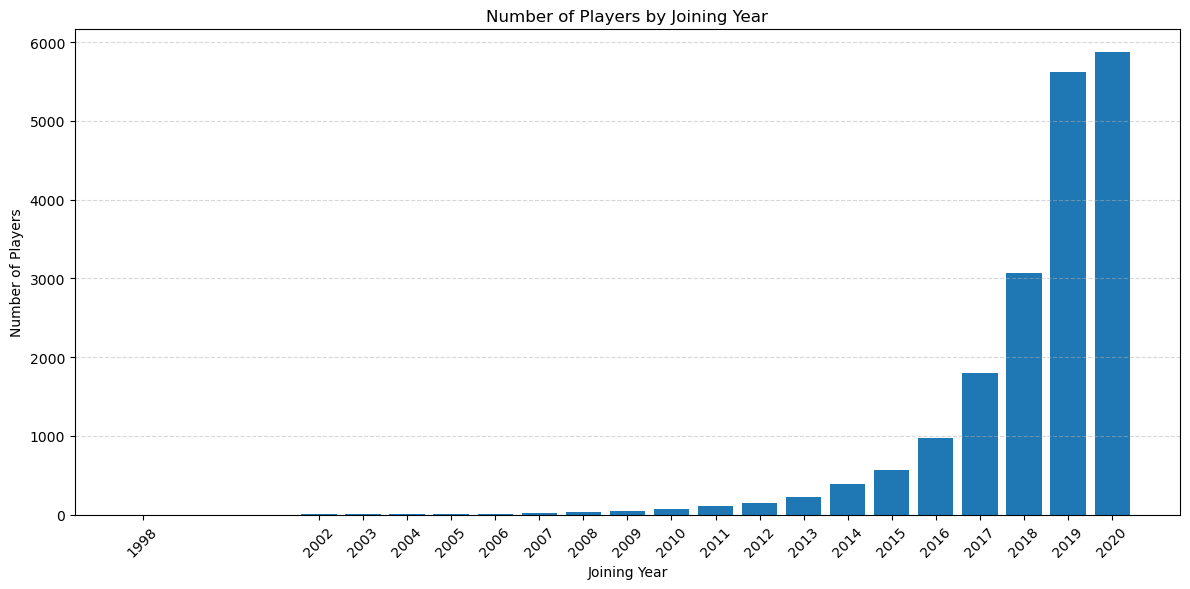

In [41]:
import matplotlib.pyplot as plt

# Count players by joining year
year_counts = df["Joined_Year"].value_counts().sort_index()

# Create a bar chart
plt.figure(figsize=(12, 6))
plt.bar(year_counts.index, year_counts.values)

plt.title("Number of Players by Joining Year")
plt.xlabel("Joining Year")
plt.ylabel("Number of Players")
plt.xticks(year_counts.index, rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### Visualizing player records by joining year

I create a bar chart to compare the number of player records across joining years. The chart makes it easier to see the distribution over time and highlights the larger counts in the most recent years represented in this dataset.

This is a descriptive view of the dataset, not a measure of all transfers in world football.

### Reviewing the updated dataset structure

After creating additional contract and joining-date features, I inspect the DataFrame again. The original dataset had 75 columns; the new columns created so far increase the number of columns. I use `df.info()` to review the current row count, column count, data types, and non-null counts before continuing with the remaining attributes.

In [42]:
# Inspect remaining columns and their data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18979 entries, 0 to 18978
Data columns (total 83 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   ID                   18979 non-null  int64         
 1   Name                 18979 non-null  object        
 2   LongName             18979 non-null  object        
 3   photoUrl             18979 non-null  object        
 4   playerUrl            18979 non-null  object        
 5   Nationality          18979 non-null  object        
 6   Age                  18979 non-null  int64         
 7   POT                  18979 non-null  int64         
 8   Contract             18979 non-null  object        
 9   Positions            18979 non-null  object        
 10  Height               18979 non-null  float64       
 11  Weight               18979 non-null  float64       
 12  Preferred Foot       18979 non-null  object        
 13  BOV                  18979 non-

In [43]:
# Inspect the Hits column
print("Data type:", df["Hits"].dtype)

print("\nMissing values:", df["Hits"].isnull().sum())

print("\nUnique values:", df["Hits"].nunique())

print("\nMost frequent values:")
display(df["Hits"].value_counts().head(20))

Data type: object

Missing values: 2595

Unique values: 450

Most frequent values:


Hits
1     2325
2     2240
3     1729
4     1247
5      936
6      750
7      583
8      514
9      468
10     340
11     307
12     267
13     234
14     222
15     214
16     177
17     149
18     143
20     131
19     127
Name: count, dtype: int64

## 8. Cleaning the Hits column

I inspect the `Hits` column to understand its data type, missing values, number of unique values, and most frequent entries. The column represents the profile-view count recorded for each player in the dataset.

Although the values are numeric in meaning, they are stored as text. Some values also use the suffix `K` to represent thousands. I need to identify the formats before converting the column.

In [44]:
# Display some unique values
display(df["Hits"].dropna().unique()[:50])

array(['771', '562', '150', '207', '595', '248', '246', '120', '1.6K',
       '130', '321', '189', '175', '96', '118', '216', '212', '154',
       '205', '202', '339', '408', '103', '332', '86', '173', '161',
       '396', '1.1K', '433', '242', '206', '177', '1.5K', '198', '459',
       '117', '119', '209', '84', '187', '165', '203', '65', '336', '126',
       '313', '124', '145', '538'], dtype=object)

### Inspecting Hits value formats

I inspect a sample of unique, non-missing values to identify how the `Hits` values are represented. The sample includes ordinary numeric strings, such as `771`, and abbreviated values, such as `1.6K`.

I interpret `K` as one thousand, so `1.6K` should become `1600`. Missing values need to remain missing unless there is evidence that they represent zero views.

### Counting values abbreviated with K

I count the non-missing `Hits` values that contain the `K` suffix. This gives me an idea of how many values need the thousands conversion rule. I perform this check before applying the conversion function.

In [45]:
# Count values containing K
k_values = df["Hits"].dropna().str.contains("K").sum()

print("Number of values containing K:", k_values)

Number of values containing K: 28


In [46]:
# Define a function to convert Hits values into numbers
def convert_hits(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip()

    if value.endswith("K"):
        return float(value[:-1]) * 1000

    return float(value)


# Apply the function
df["Hits"] = df["Hits"].apply(convert_hits)

# Convert to nullable integer type
df["Hits"] = df["Hits"].astype("Int64")

### Converting Hits into numerical values

I create a custom function to handle the different formats in `Hits`. The function first checks whether a value is missing. For non-missing values, it converts the value to a string and removes surrounding whitespace.

If the value ends with `K`, I remove the suffix, convert the remaining part to a number, and multiply it by 1,000. Otherwise, I convert the value directly to a number. Finally, I use Pandas' nullable `Int64` data type so the column can contain integers while preserving missing values.

In [47]:
# Check the transformed Hits column
print("Data type:", df["Hits"].dtype)

print("Missing values:", df["Hits"].isnull().sum())

print("Unique values:", df["Hits"].nunique())

# Inspect the largest values
print("\nTop 10 highest Hits:")
display(df["Hits"].nlargest(10))

# Descriptive statistics
print("\nDescriptive statistics:")
display(df["Hits"].describe())

Data type: Int64
Missing values: 2595
Unique values: 439

Top 10 highest Hits:


2579     8400
15819    6000
3791     4300
68       3200
690      3000
1265     2800
8401     2500
106      2300
4800     2300
416      2000
Name: Hits, dtype: Int64


Descriptive statistics:


count       16384.0
mean       26.56958
std      128.631295
min             1.0
25%             2.0
50%             5.0
75%            15.0
max          8400.0
Name: Hits, dtype: Float64

### Validating the Hits transformation

I check the resulting data type, missing-value count, and number of unique values. I also inspect the largest values and descriptive statistics to verify that the abbreviated values were converted into a numerical scale.

The `Int64` dtype is Pandas' nullable integer type, which allows the column to contain both integer values and missing values.

### Decision on missing values in Hits

After conversion, the `Hits` column still contains **2,595 missing values**, or approximately **13.67%** of the 18,979 player records.

I keep these values missing rather than replacing them with zero or the median. A missing value does not necessarily mean that a player's profile received zero views; it may mean that the information was not recorded. Preserving the missing values avoids making an unsupported assumption.

If this column is later used for machine learning, I will decide how to handle missing values as part of the modeling workflow and based on the intended use of the feature.

## 7. Reviewing Weak Foot (W/F)

Before transforming `W/F`, I inspect its data type, missing values, number of unique values, and frequency distribution. This helps me confirm that the values are consistently represented and understand the rating categories.

In [48]:
# Inspect the W/F column
print("Data type:", df["W/F"].dtype)

print("\nMissing values:", df["W/F"].isnull().sum())

print("\nUnique values:", df["W/F"].nunique())

print("\nValue counts:")
display(df["W/F"].value_counts())

Data type: object

Missing values: 0

Unique values: 5

Value counts:


W/F
3 ★    11695
2 ★     4141
4 ★     2722
5 ★      283
1 ★      138
Name: count, dtype: int64

## 9. Cleaning the Weak Foot (W/F) column

The `W/F` column represents a player's weak-foot rating. My inspection shows five possible ratings, from one to five stars, and no missing values.

The ratings are stored as text with a star symbol, for example `3 ★`. Since the star symbol is only a label and the rating itself is numeric, I will remove the symbol and convert the values to integers.

In [49]:
# Remove the star symbol and convert values to integers
df["W/F"] = df["W/F"].str.replace("★", "", regex=False).str.strip().astype(int)

# Inspect the transformed column
display(df["W/F"].value_counts().sort_index())

W/F
1      138
2     4141
3    11695
4     2722
5      283
Name: count, dtype: int64

### Cleaning the Weak Foot column

I remove the star symbol from the `W/F` values using `str.replace()`, remove any surrounding whitespace using `str.strip()`, and convert the remaining values to integers with `astype(int)`.

This preserves the original rating scale from 1 to 5 while making the column numeric.

In [50]:
# Validate the transformation
print("Data type:", df["W/F"].dtype)
print("Missing values:", df["W/F"].isnull().sum())
print("Unique values:", sorted(df["W/F"].unique()))

display(df["W/F"].describe())

Data type: int64
Missing values: 0
Unique values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


count    18979.000000
mean         2.940513
std          0.668449
min          1.000000
25%          3.000000
50%          3.000000
75%          3.000000
max          5.000000
Name: W/F, dtype: float64

### Validating the Weak Foot transformation

I check the data type, missing values, unique ratings, and descriptive statistics after the conversion. The expected result is an integer column containing the five ratings from 1 to 5, with no missing values.

## 8. Reviewing Skill Moves (SM)

Before cleaning `SM`, I inspect its data type, missing values, unique values, and frequency distribution. This tells me whether the ratings follow a consistent format and whether any missing-value handling is required.

In [51]:
# Inspect the SM column
print("Data type:", df["SM"].dtype)
print("Missing values:", df["SM"].isnull().sum())
print("Unique values:", df["SM"].nunique())

display(df["SM"].value_counts())

Data type: object
Missing values: 0
Unique values: 5


SM
2★    9142
3★    6577
1★    2075
4★    1130
5★      55
Name: count, dtype: int64

## 10. Cleaning the Skill Moves (SM) column

The `SM` column represents a player's skill-moves rating. The inspection shows five possible ratings, from one to five stars, and no missing values.

The values are stored as strings with a star symbol, such as `2★`. I will remove the symbol and convert the ratings into integers, following the same approach used for `W/F`.

In [52]:
# Remove the star symbol and convert values to integers
df["SM"] = df["SM"].str.replace("★", "", regex=False).astype(int)

# Inspect the results
display(df["SM"].value_counts().sort_index())

SM
1    2075
2    9142
3    6577
4    1130
5      55
Name: count, dtype: int64

### Cleaning the Skill Moves column

I remove the star symbol from the `SM` values using `str.replace()` and convert the remaining numeric strings into integers using `astype(int)`.

This keeps the original 1-to-5 rating scale and makes the column suitable for numerical summaries and analysis.

In [53]:
# Validate the transformation
print("Data type:", df["SM"].dtype)
print("Missing values:", df["SM"].isnull().sum())
print("Unique values:", sorted(df["SM"].unique()))

display(df["SM"].describe())

Data type: int64
Missing values: 0
Unique values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


count    18979.000000
mean         2.364982
std          0.766114
min          1.000000
25%          2.000000
50%          2.000000
75%          3.000000
max          5.000000
Name: SM, dtype: float64

### Validating the Skill Moves transformation

I verify the resulting data type, missing-value count, unique ratings, and descriptive statistics. This confirms whether the star symbols were removed and the ratings were converted successfully.

## 11. Reviewing Attacking Work Rate (A/W)

I inspect the `A/W` column before deciding whether to transform it. I check its data type, missing values, unique categories, and category frequencies.

In [54]:
# Inspect the A/W column
print("Data type:", df["A/W"].dtype)
print("Missing values:", df["A/W"].isnull().sum())
print("Unique values:", df["A/W"].nunique())

print("\nValue counts:")
display(df["A/W"].value_counts())

Data type: object
Missing values: 0
Unique values: 3

Value counts:


A/W
Medium    12701
High       5288
Low         990
Name: count, dtype: int64

## 11. Reviewing Attacking Work Rate (A/W)

The `A/W` column describes a player's attacking work rate. My inspection found three categories: `High`, `Medium`, and `Low`, with no missing values.

These are meaningful categorical labels rather than numerical measurements. I will therefore preserve the labels instead of assigning arbitrary numbers to them.

In [55]:
# Check the categories and their frequencies
print("Data type:", df["A/W"].dtype)

print("\nUnique categories:")
print(df["A/W"].unique())

print("\nCategory distribution:")
display(df["A/W"].value_counts())

Data type: object

Unique categories:
['Medium' 'High' 'Low']

Category distribution:


A/W
Medium    12701
High       5288
Low         990
Name: count, dtype: int64

### Decision: preserve Attacking Work Rate as categorical data

I reviewed the categories and their frequencies in `A/W`. The column contains `High`, `Medium`, and `Low`, and no missing values.

Because the labels already represent meaningful categories, I leave the values unchanged. If I later prepare the data for a machine learning model, I can choose an encoding method that suits that model and analysis.

## 12. Reviewing Defensive Work Rate (D/W)

I inspect the `D/W` column before deciding whether it needs any transformation. I check its data type, missing values, number of unique categories, and category frequencies.

In [56]:
# Inspect the D/W column
print("Data type:", df["D/W"].dtype)
print("Missing values:", df["D/W"].isnull().sum())
print("Unique values:", df["D/W"].nunique())

print("\nValue counts:")
display(df["D/W"].value_counts())

Data type: object
Missing values: 0
Unique values: 3

Value counts:


D/W
Medium    13956
High       3297
Low        1726
Name: count, dtype: int64

## 12. Reviewing Defensive Work Rate (D/W)

The `D/W` column describes a player's defensive work rate. I inspect its data type, missing values, unique categories, and frequency distribution to determine whether it needs cleaning.

As with `A/W`, these values are categorical labels, so I will preserve them if the categories are consistent.

In [57]:
# Inspect defensive work rate categories
print("Data type:", df["D/W"].dtype)

print("\nUnique categories:")
print(df["D/W"].unique())

print("\nCategory distribution:")
display(df["D/W"].value_counts())

Data type: object

Unique categories:
['Low' 'Medium' 'High']

Category distribution:


D/W
Medium    13956
High       3297
Low        1726
Name: count, dtype: int64

### Decision: preserve Defensive Work Rate as categorical data

The `D/W` column contains three categories: `High`, `Medium`, and `Low`, with no missing values. These labels are already clear and meaningful, so I keep the column unchanged rather than converting the categories into arbitrary numerical codes.

## 11. Reviewing International Reputation (IR)

Before transforming `IR`, I inspect its data type, missing values, unique values, and frequency distribution. This helps me confirm how the ratings are represented and whether the column needs cleaning.

In [58]:
# Inspect the IR column
print("Data type:", df["IR"].dtype)
print("Missing values:", df["IR"].isnull().sum())
print("Unique values:", df["IR"].nunique())

print("\nValue counts:")
display(df["IR"].value_counts())

Data type: object
Missing values: 0
Unique values: 5

Value counts:


IR
1 ★    17629
2 ★     1018
3 ★      281
4 ★       45
5 ★        6
Name: count, dtype: int64

## 13. Cleaning International Reputation (IR)

The `IR` column represents a player's International Reputation rating. The inspection shows five possible ratings, from one to five stars, and no missing values.

The ratings are stored as strings with a star symbol, such as `1 ★`. I will remove the symbol and convert the ratings into integers, as I did with the `W/F` and `SM` columns.

In [59]:
# Remove the star symbol and convert values to integers
df["IR"] = df["IR"].str.replace("★", "", regex=False).str.strip().astype(int)

# Inspect the results
display(df["IR"].value_counts().sort_index())

IR
1    17629
2     1018
3      281
4       45
5        6
Name: count, dtype: int64

### Cleaning the International Reputation column

I remove the star symbol using `str.replace()`, remove any surrounding whitespace using `str.strip()`, and convert the remaining values into integers using `astype(int)`.

This preserves the original 1-to-5 rating scale while changing the data type from object to integer.

In [60]:
# Validate the transformation
print("Data type:", df["IR"].dtype)
print("Missing values:", df["IR"].isnull().sum())
print("Unique values:", sorted(df["IR"].unique()))

display(df["IR"].describe())

Data type: int64
Missing values: 0
Unique values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


count    18979.000000
mean         1.091628
std          0.361760
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          5.000000
Name: IR, dtype: float64

### Validating the International Reputation transformation

I check the data type, missing values, unique ratings, and descriptive statistics after the conversion. This allows me to confirm that the `IR` column now contains numerical ratings and that the transformation has not introduced missing values.

## 12. Progress summary and next steps

### Work completed so far

In this stage of the project, I have inspected and transformed several columns:

| Column | Work completed |
|---|---|
| `Value` | Converted euro amounts with `M` and `K` suffixes into numerical values |
| `Wage` | Reused the financial-value conversion logic |
| `Release Clause` | Reused the financial-value conversion logic |
| `Weight` | Standardized kilograms and pounds to kilograms |
| `Height` | Standardized centimeters and feet/inches to centimeters |
| `Contract` | Created contract status, extracted contract years and loan end dates, and calculated contract duration |
| `Joined` | Converted text dates to datetime and extracted year and month features |
| `Hits` | Converted abbreviated values such as `1.6K` to integers while preserving missing values |
| `W/F` | Removed the star symbol and converted ratings to integers |
| `SM` | Removed the star symbol and converted ratings to integers |
| `A/W` | Reviewed and preserved the High/Medium/Low categories |
| `D/W` | Reviewed and preserved the High/Medium/Low categories |
| `IR` | Removed the star symbol and converted ratings to integers |

### Important decisions

- I standardized measurement units rather than keeping mixed units in the same column.
- I preserved missing values when their meaning was unknown instead of automatically replacing them with zero.
- I kept meaningful categorical labels as categories rather than assigning arbitrary numerical values.
- I validated transformations by checking data types, missing values, unique values, and sample records.

### Next steps

This notebook is still in progress. I will continue inspecting the remaining columns, review missing values and possible inconsistencies, and perform a final validation of the cleaned dataset. Before using the dataset for analysis or machine learning, I will also review the new features and decide whether any additional preprocessing is necessary.